# Simple GemPy model from borehole data

Build a 3D geological model of four layers from boreholes at different positions.

Each borehole gives its position (x, y) and the depth to the base of Layers 1, 2 and 3. Layer 4 lies below Layer 3. In GemPy each surface marks the **bottom** of a layer, so the base of each layer becomes a set of surface points, and the lowest layer is the remaining volume (the *basement*).

Replace the table in section 1 with your own boreholes.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gempy as gp
import gempy_viewer as gpv


## 1. Borehole data

Coordinates in metres. Depths are metres below the ground surface, which is at z = 0. The layers dip slightly towards the east.

In [12]:
boreholes = pd.DataFrame({
    'name':    ['BH1', 'BH2', 'BH3', 'BH4', 'BH5', 'BH6', 'BH7', 'BH8'],
    'x':       [100, 500, 900, 100, 500, 900, 300, 700],
    'y':       [100, 100, 100, 500, 500, 500, 900, 900],
    'base_L1': [8, 12, 16, 9, 13, 18, 10, 15],
    'base_L2': [25, 31, 38, 27, 33, 40, 29, 36],
    'base_L3': [48, 55, 63, 50, 58, 66, 53, 61],
})
boreholes

,name,x,y,base_L1,base_L2,base_L3
0,BH1,100,100,8,25,48
1,BH2,500,100,12,31,55
2,BH3,900,100,16,38,63
3,BH4,100,500,9,27,50
4,BH5,500,500,13,33,58
5,BH6,900,500,18,40,66
6,BH7,300,900,10,29,53
7,BH8,700,900,15,36,61


Map of the boreholes.

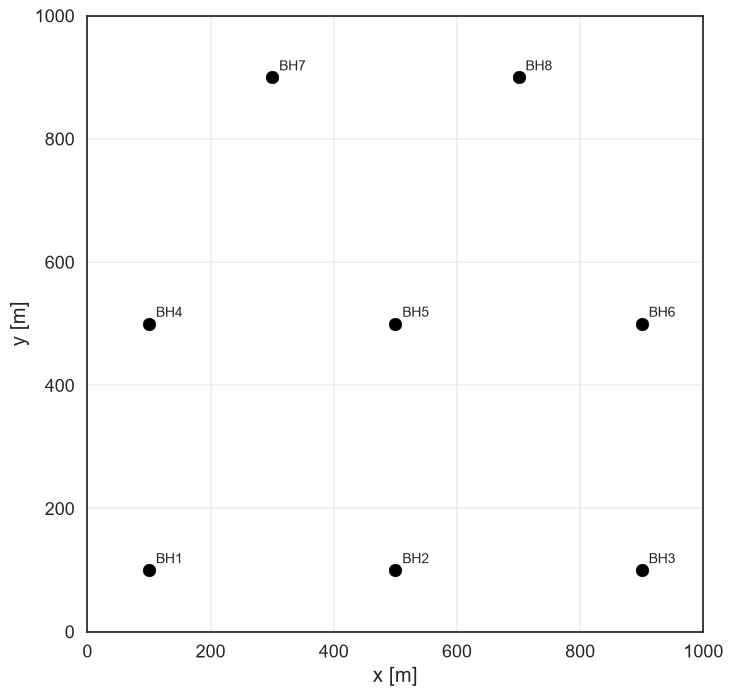

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(boreholes['x'], boreholes['y'], c='k')
for _, b in boreholes.iterrows():
    ax.annotate(b['name'], (b['x'], b['y']), textcoords='offset points', xytext=(5, 5))
ax.set(xlabel='x [m]', ylabel='y [m]', xlim=(0, 1000), ylim=(0, 1000), aspect='equal')
ax.grid(alpha=0.3)
plt.show()

## 2. Create the model

The extent must enclose all data. `initialize_default_structure()` gives one placeholder layer and the basement, in one group. These are renamed to Layer 1 and Layer 4; Layers 2 and 3 are added below.

In [14]:
geo_model = gp.create_geomodel(
    project_name='boreholes',
    extent=[0, 1000, 0, 1000, -100, 0],
    resolution=(50, 50, 50),
    structural_frame=gp.data.StructuralFrame.initialize_default_structure(),
)

frame = geo_model.structural_frame
frame.structural_groups[0].name = 'Strata'
frame.structural_elements[0].name = 'Layer 1'
frame.structural_elements[0].color = '#33ABFF'
frame.structural_elements[1].name = 'Layer 4'
frame.structural_elements[1].color = '#570987'
frame.structural_elements

[Element(
 	name=Layer 1,
 	color=#33ABFF,
 	is_active=True
 ),
 Element(
 	name=basement,
 	color=#9f0052,
 	is_active=True
 )]

## 3. Add the borehole data

The base of Layer 1 goes into the existing layer. Layers 2 and 3 are new layers, each created from the base depths of its own boreholes and added to the same group. Depths become negative z values.

In [15]:
x = boreholes['x'].to_numpy()
y = boreholes['y'].to_numpy()

# Base of Layer 1
gp.add_surface_points(geo_model=geo_model, x=x.tolist(), y=y.tolist(),
                      z=(-boreholes['base_L1']).tolist(),
                      elements_names=['Layer 1'] * len(boreholes))

# Base of Layers 2 and 3
for name, column, color in [('Layer 2', 'base_L2', '#FFA833'),
                            ('Layer 3', 'base_L3', '#72A533')]:
    element = gp.data.StructuralElement(
        name=name,
        color=color,
        surface_points=gp.data.SurfacePointsTable.from_arrays(
            x=x, y=y, z=-boreholes[column].to_numpy(), names=name),
        orientations=gp.data.OrientationsTable.initialize_empty(),
    )
    frame.structural_groups[0].append_element(element)

# One orientation is needed: assume the layers are roughly horizontal
gp.add_orientations(geo_model=geo_model, x=[500], y=[500], z=[-30],
                    elements_names=['Layer 1'], pole_vector=[np.array([0, 0, 1])])

frame.structural_elements

[Element(
 	name=Layer 1,
 	color=#33ABFF,
 	is_active=True
 ),
 Element(
 	name=Layer 2,
 	color=#FFA833,
 	is_active=True
 ),
 Element(
 	name=Layer 3,
 	color=#72A533,
 	is_active=True
 ),
 Element(
 	name=basement,
 	color=#9f0052,
 	is_active=True
 )]

Input data in an x-z cross-section (points projected onto the plane) and a plan-view map with borehole locations.


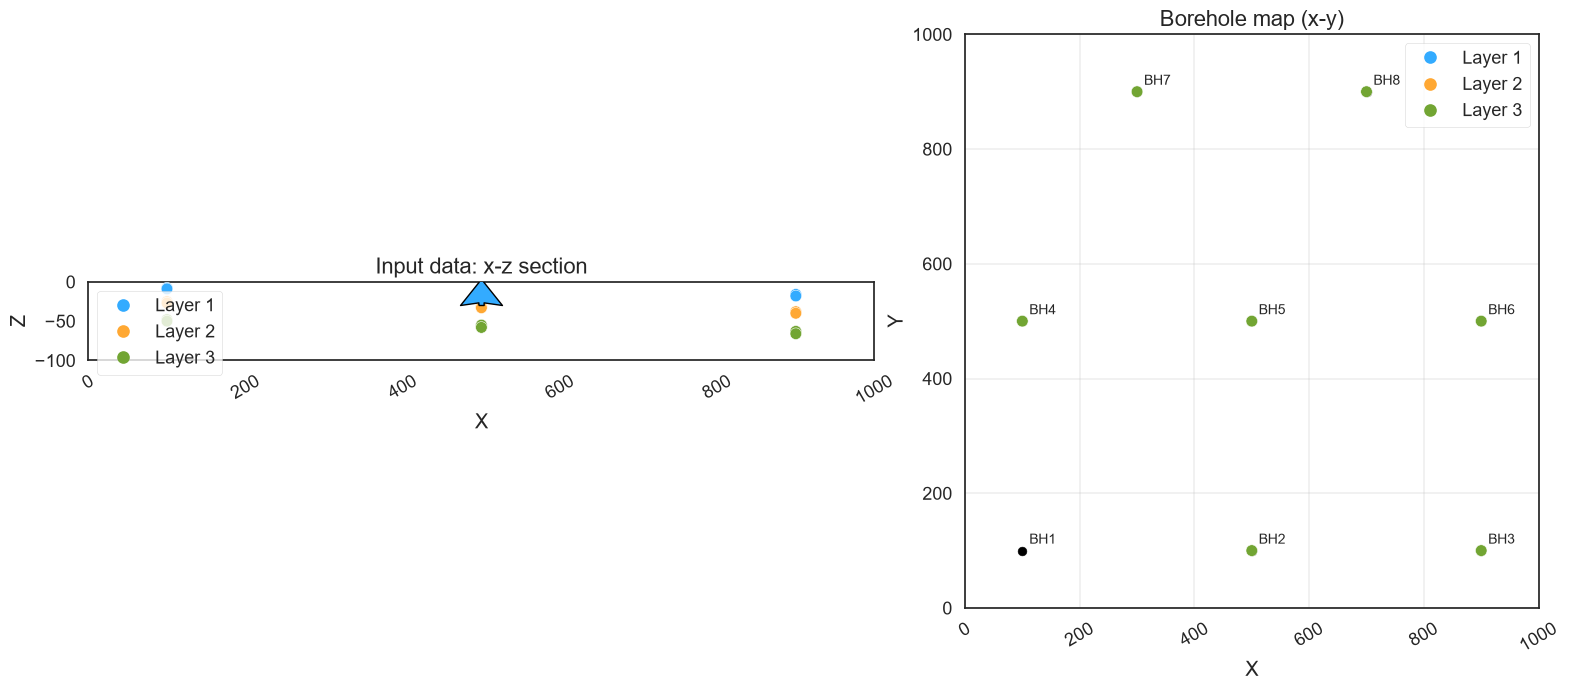

In [16]:
plot = gpv.plot_2d(
    geo_model,
    direction=['y', 'z'],
    cell_number=['mid', -1],
    show_lith=False,
    show_boundaries=False,
    show=False,
    figsize=(16, 7),
)
fig, ax = plot.fig, plot.axes
ax[0].set_title('Input data: x-z section')
ax[1].set_title('Borehole map (x-y)')
ax[1].scatter(boreholes['x'], boreholes['y'], c='k', s=40, zorder=10)
for _, b in boreholes.iterrows():
    ax[1].annotate(b['name'], (b['x'], b['y']),
                   textcoords='offset points', xytext=(5, 5), zorder=11)
ax[1].set_aspect('equal')
ax[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()


## 4. Compute the model

In [17]:
gp.compute_model(geo_model)

Setting Backend To: AvailableBackends.numpy


c:\Users\pamcl\OneDrive - Danmarks Tekniske Universitet\Dokumenter\Projects\Python\Edcrop\.venv-2\Lib\site-packages\gempy_engine\core\data\transforms.py:217: RuntimeWarning: Interpolation is being done with the default transform. If you do not know what you are doing you should probably call GeoModel.update_transform() first.
  warnings.warn(


Chunking done: 7 chunks


Solutions(4 Octree Levels, 3 DualContouringMeshes)

## 5. Results

Cross-sections through the middle of the model in the x-z and y-z planes, plus an x-y geological map of the uppermost grid slice with borehole locations.

The map shows labelled A-A' and B-B' transects at the actual grid coordinates of the two displayed midpoint cross-sections.


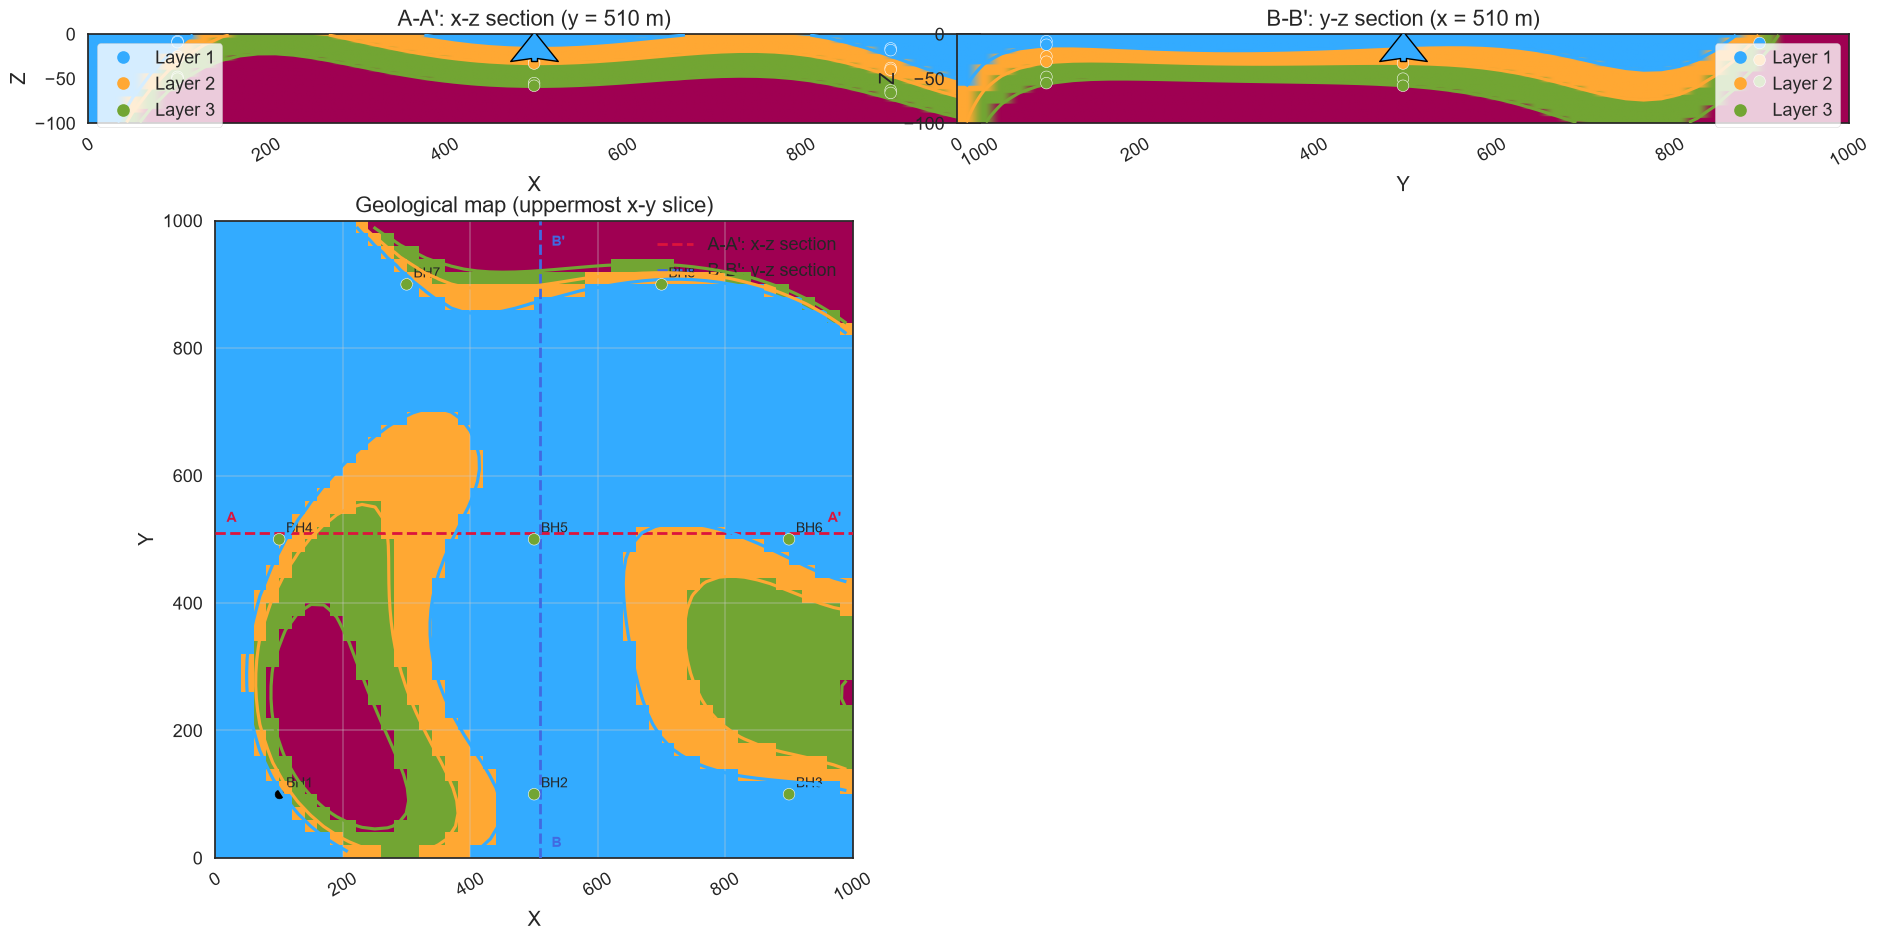

In [18]:
plot = gpv.plot_2d(
    geo_model,
    direction=['y', 'x', 'z'],
    cell_number=['mid', 'mid', -1],
    show=False,
    figsize=(18, 12),
)
fig, ax = plot.fig, plot.axes
for section_ax, title in zip(
    ax, ['x-z section (mid y)', 'y-z section (mid x)',
         'Geological map (uppermost x-y slice)']
):
    section_ax.set_title(title)
ax[2].scatter(boreholes['x'], boreholes['y'], c='k', s=40, zorder=10)
for _, b in boreholes.iterrows():
    ax[2].annotate(b['name'], (b['x'], b['y']),
                   textcoords='offset points', xytext=(5, 5), zorder=11)
# Use the actual midpoint grid cells shown in the two sections.
grid = geo_model.grid.regular_grid
nx, ny, nz = grid.resolution
grid_xyz = grid.values.reshape(nx, ny, nz, 3)
section_x = grid_xyz[nx // 2, 0, 0, 0]
section_y = grid_xyz[0, ny // 2, 0, 1]

ax[2].axhline(section_y, color='crimson', linestyle='--', linewidth=2,
               label="A-A': x-z section", zorder=12)
ax[2].axvline(section_x, color='royalblue', linestyle='--', linewidth=2,
               label="B-B': y-z section", zorder=12)
for label, xy, offset, color in [
    ('A', (grid.extent[0], section_y), (8, 8), 'crimson'),
    ("A'", (grid.extent[1], section_y), (-18, 8), 'crimson'),
    ('B', (section_x, grid.extent[2]), (8, 8), 'royalblue'),
    ("B'", (section_x, grid.extent[3]), (8, -18), 'royalblue'),
]:
    ax[2].annotate(label, xy, textcoords='offset points', xytext=offset,
                   color=color, fontweight='bold', zorder=13)
ax[0].set_title(f"A-A': x-z section (y = {section_y:g} m)")
ax[1].set_title(f"B-B': y-z section (x = {section_x:g} m)")
ax[2].legend(loc='upper right')
ax[2].set_aspect('equal')
ax[2].grid(alpha=0.3)
fig.tight_layout()
plt.show()


3D view.

In [19]:
gpv.plot_3d(geo_model, image=True)

ImportError: The pyvista package is required to run this function.